In [1]:
import numpy as np
from matplotlib import pyplot as plt
import Mie as mie

In [46]:
def get_ref_data(material):
  if material == 'gra':
    wv_raw, n_raw, k_raw = np.loadtxt('ref index data/c-gra-Draine2003.download', skiprows=27, unpack=True)
  elif material == 'sic':
    wv_raw, n_raw, k_raw = np.loadtxt('ref index data/sic-Draine1993.download', skiprows=12, unpack=True)
  elif material == 'fe':
    wv_raw, n_raw, k_raw =  np.loadtxt('ref index data/fe-c-Henning1996.download', skiprows= 12, unpack = True)
  elif material == 'h2o':
    wv_raw, n_raw, k_raw =  np.loadtxt('ref index data/h2o-w-Warren2008.lnk', skiprows= 27, unpack = True)
  else:
    print('not applicable material')
    
    pass
  return wv_raw, n_raw, k_raw

In [47]:
# Take refractive index data from file for calculation
#wv_raw, n_raw, k_raw =  np.loadtxt('Wang-4H-o.txt', skiprows= 1, unpack = True)
wv_raw, n_raw, k_raw = np.loadtxt('ref index data/c-gra-Draine2003.download', skiprows=27, unpack=True)
#wv_raw, n_raw, k_raw = np.loadtxt('sic-Draine1993.download', skiprows=28, unpack=True)


#optool data to compare to
#wavelength, ka, ks, g = np.loadtxt('dustkappa-gra-1um.dat', skiprows=24, unpack=True)

wv_raw, n_raw, k_raw = get_ref_data('h2o')

#k_raw = 0.000001 * (wv_raw*np.ones_like(n_raw))**0.4
#n_raw = 0.000001 * (wv_raw*np.ones_like(n_raw))**0.4
wv, m = mie.interp_m(wv_raw, n_raw, k_raw, wv_range = [5e-2, 10**6], num_points = 1000)
#m = (1.0 + 0.1*wv*1j) * np.ones_like(m)


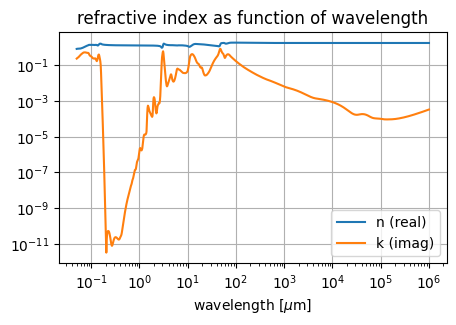

In [48]:
# @title Plot refractive index from file
fig, ax = plt.subplots(1, figsize = [5,3])

ax.plot(wv, m.real, label = 'n (real)')
ax.plot(wv, abs(m.imag), label = 'k (imag)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.grid()
ax.set_title('refractive index as function of wavelength')
ax.set_xlabel(r'wavelength [$\mu$m]')

x_line = np.logspace(np.log10(min(wv)),np.log10(max(wv)),100)
y_line = 10*(x_line / 10)**0.75

mask = np.where((x_line >1) & (x_line < 100000))

#ax.plot(x_line[mask], y_line[mask], color = 'black', label = "")

ax.legend(loc = 'best')

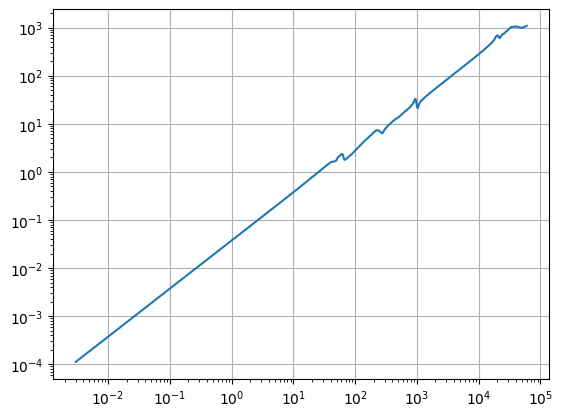

In [53]:
plt.plot(3000/wv, 10*abs(m)*2*np.pi/wv)
plt.yscale('log')
plt.xscale('log')
plt.grid()

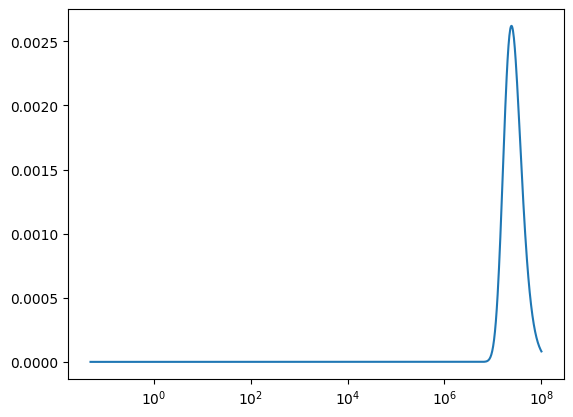

In [118]:
plt.plot(wv,mie.dB_lambda_dT(wv,0.0001))
plt.xscale('log')

In [49]:
x_plot = wv
a = 10

 # give in micrometers
a = float(a)
y_plot = mie.get_efficiencies(m, x_plot, a)


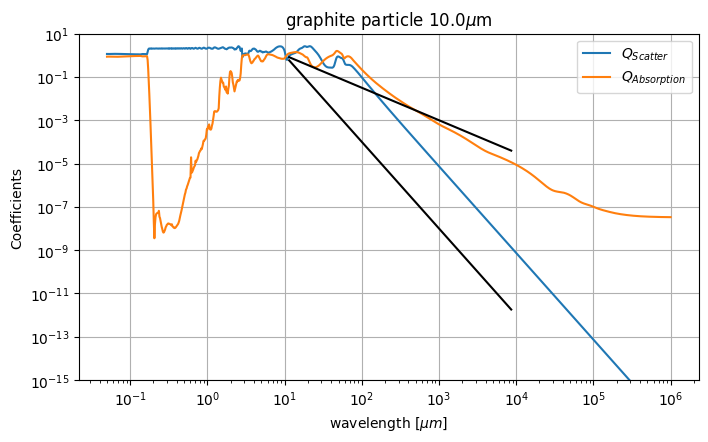

In [50]:
fig, ax = plt.subplots(1, figsize=(8, 4.5))
ax.plot(x_plot, y_plot[0], label = r'$Q_{Scatter}$')
ax.plot(x_plot, y_plot[1]-y_plot[0], label = r'$Q_{Absorption}$')
ax.legend(loc ='best')
ax.set_xlabel(r'wavelength [$\mu m$]')
ax.set_ylabel(r'Coefficients')
ax.set_title(f'graphite particle {a}'+ r'$\mu$m')
x_line = np.logspace(np.log10(min(wv)),np.log10(max(wv)),100)
y_line = 10*(x_line / 10)**-1.5

mask = np.where((x_line >10) & (x_line < 10000))
ax.plot(x_line[mask], y_line[mask]/a, color = 'black', label = "")

y_line = 10*(x_line / 10)**-4

ax.plot(x_line[mask], y_line[mask]/a, color = 'black', label = "")

#ax.set_xlim(0.4,1)
ax.set_ylim(10**-15, 10)
ax.set_xscale('log')
ax.set_yscale('log')
ax.grid()

In [168]:
mie_interp, nd_mie_arr, size_arr, wv_arr =  mie.create_mie_interp([2e-3, 1000], [1e-3, 2.5], wv_raw, n_raw, k_raw, 300, 100)

100%|██████████| 100/100 [00:10<00:00,  9.20it/s]


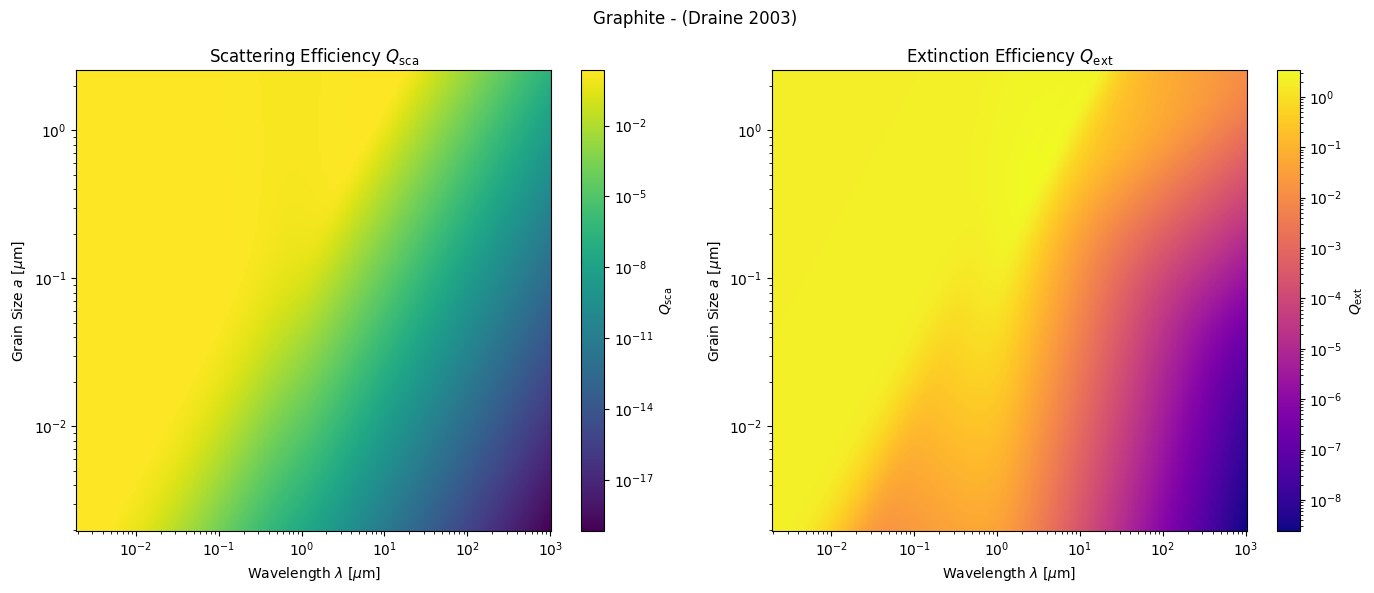

In [169]:
import numpy as np
import matplotlib.pyplot as plt

# Define ranges for grain size 'a' and wavelength 'wv'
a_grid = np.logspace(np.log10(2e-3), np.log10(2.5), 200) # 1e-3 to 10 um
wv_grid = np.logspace(np.log10(2e-3), 3, 200) # 1e-3 to 1000 um

# Create 2D meshgrid
A, WV = np.meshgrid(a_grid, wv_grid, indexing='ij')

# Flatten and stack to feed into the interpolator
coords = np.column_stack((A.ravel(), WV.ravel()))
vals = mie_interp(coords)

# Reshape results back to 2D grids
qsca_grid = vals[:, 0].reshape(A.shape)
qext_grid = vals[:, 1].reshape(A.shape)

# Create 2D plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Plot Q_sca
im1 = axes[0].pcolormesh(WV, A, qsca_grid, shading='auto', cmap='viridis', norm = 'log')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel(r'Wavelength $\lambda$ [$\mu$m]')
axes[0].set_ylabel(r'Grain Size $a$ [$\mu$m]')
axes[0].set_title(r'Scattering Efficiency $Q_{\rm sca}$')
fig.colorbar(im1, ax=axes[0], label=r'$Q_{\rm sca}$')

# Plot Q_ext
im2 = axes[1].pcolormesh(WV, A, qext_grid, shading='auto', cmap='plasma', norm = 'log')
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel(r'Wavelength $\lambda$ [$\mu$m]')
axes[1].set_ylabel(r'Grain Size $a$ [$\mu$m]')
axes[1].set_title(r'Extinction Efficiency $Q_{\rm ext}$')
fig.colorbar(im2, ax=axes[1], label=r'$Q_{\rm ext}$')
fig.suptitle('Graphite - (Draine 2003)')

plt.tight_layout()
plt.show()

In [127]:
mie_interp, nd_mie_arr, beae, asd =  mie.create_mie_interp([5e-3, 100000000], [1e-3, 20], wv_raw, n_raw, k_raw, 1000, 40)

Past limits of reference data, a slope is extrapolated to continue the set.


100%|██████████| 40/40 [00:18<00:00,  2.13it/s]


In [13]:
wv, m = mie.interp_m(wv_raw, n_raw, k_raw, [5e-2, 1000], 500)
a = np.logspace(np.log10(1e-3), np.log10(3), 40)
temp_plot = np.logspace(np.log10(10),np.log10(3000000), 100)
k_plot = np.zeros(len(temp_plot))
kr_plot = np.zeros(len(temp_plot))
kp_plot = np.zeros(len(temp_plot))

dist = lambda r : mie.pwr_law(r, 3.5, cutoff_low = 0.005, cutoff_high = 2.5, total = 1)

dist = lambda r : mie.std_dist(r)

for i in range(0, len(temp_plot)):
  k_plot[i] =  mie.get_planck(a, wv, dist, temp_plot[i], mie_interp)
  kp_plot[i] = mie.get_planck_flipped(a, wv, dist, temp_plot[i], mie_interp)
  kr_plot[i] = mie.get_rosseland(a, wv, dist, temp_plot[i], mie_interp)


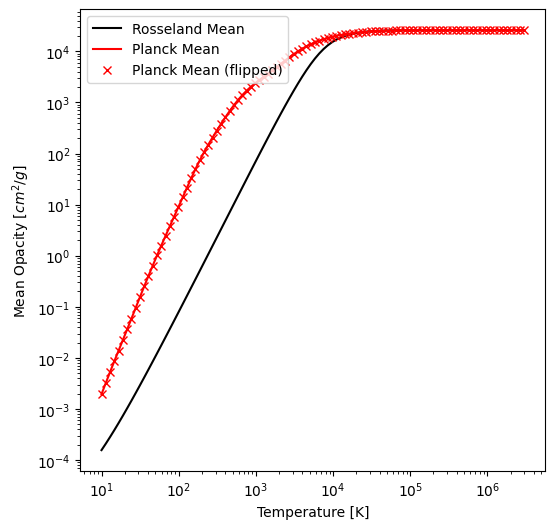

In [14]:
fig, ax = plt.subplots(1, figsize = [6,6])

#ax.plot(temp_plot, k_plot)
ax.plot(temp_plot, kr_plot, label = r'Rosseland Mean', color = 'black')
ax.plot(temp_plot, k_plot, label = r'Planck Mean', color = 'red')
ax.plot(temp_plot, kp_plot, 'x',label = r'Planck Mean (flipped)', color = 'red')
ax.set_title('')
ax.set_xlabel('Temperature [K]')
ax.set_ylabel(r'Mean Opacity [$cm^2/g$]')
ax.set_yscale('log')
ax.set_xscale('log')

ax.legend(loc = 'upper left')

In [51]:
mie_interp, nd_mie_arr, beae, asd =  mie.create_mie_interp([5e-3, 10**6], [1e-3, 20], wv_raw, n_raw, k_raw, 1000, 40)

N = 4

points = np.logspace(np.log10(5e-3), np.log10(20), N)

temp_plot = np.logspace(np.log10(10**-1),np.log10(10**5), 200)
k_plot = np.zeros([len(temp_plot),N])
for j in range(0, N-1):
  for i in range(0, len(temp_plot)):
    # Pass a lambda function to preserve the cutoff bounds while allowing get_rosseland to evaluate over the radius array
    n_dist = lambda r: mie.pwr_law(r, 3.5, cutoff_low=points[j], cutoff_high=points[j+1])
    k_plot[i][j] = mie.get_rosseland(np.logspace(np.log10(points[j]), np.log10(points[j+1]), 20), wv, n_dist, temp_plot[i], mie_interp)

100%|██████████| 40/40 [00:28<00:00,  1.38it/s]


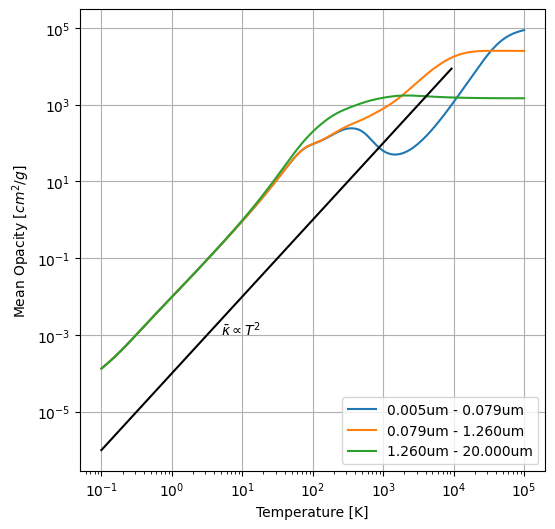

In [52]:
fig, ax = plt.subplots(1, figsize = [6,6])

#ax.plot(temp_plot, k_plot)


#temp_plot = np.logspace(np.log10(1),np.log10(1000), 200)

lab = ''
ax.plot(temp_plot, k_plot[:,0], label = f'{(points[0]):.3f}um - {(points[1]):.3f}um')

for i in range(1,N-1):
  ax.plot(temp_plot, k_plot[:,i], label = f'{(points[i]):.3f}um - {(points[i+1]):.3f}um')
  #ax.axvline(2.898e-3 * 0.5e6 / (points[i+1] +points[i]))

#ax.plot(temp_plot, k_plot[:,4], label = f'{0.5*(points[5] +points[4])}um')
#ax.axvline(2.898e-3 * 1e6 / (points[5] +points[4]))
#ax.set_title(f'bins of width {4}um')
ax.set_xlabel('Temperature [K]')
ax.set_ylabel(r'Mean Opacity [$cm^2/g$]')
ax.set_yscale('log')
ax.set_xscale('log')
ax.grid()
x_line = np.logspace(np.log10(min(temp_plot)),np.log10(max(temp_plot)),100)
y_line = 0.01*(x_line / 10)**2

ax.plot(x_line[x_line < 10000], y_line[x_line < 10000], color = 'black', label = "")
ax.text(5,0.001, r'$\bar\kappa \propto T^2$')

x_line = np.logspace(np.log10(min(temp_plot)),np.log10(max(temp_plot)),100)
y_line = 1*(x_line / 10)**2.5

#ax.plot(x_line[x_line < 10000], y_line[x_line < 10000], color = 'black', label = "")


ax.legend(loc = 'lower right')

In [ ]:
# Use the existing notebook variables
wave = wv
a_min, a_max = 5e-3, 2.5
T_grid = np.logspace(np.log10(10), np.log10(30000), 200)

# Grain-size grid for the full MRN distribution
a_full = np.logspace(np.log10(a_min), np.log10(a_max), 300)

# Reference: Rosseland mean of the full MRN distribution
k_full = np.array([
    mie.get_rosseland(a_full, wave, mie.MRN, T, mie_interp)
    for T in T_grid
])


def rosseland_by_slices(n_slices, points_per_slice=100):
    """
    Calculate the Rosseland mean in each log-spaced grain-size slice,
    then combine results using MRN mass fractions weighted by Q
    evaluated at the Wien peak wavelength of the peak temperature.
    """
    edges = np.logspace(np.log10(a_min), np.log10(a_max), n_slices + 1)

    k_slices = np.zeros((len(T_grid), n_slices))
    slice_masses = np.zeros(n_slices)
    Q_slices = np.zeros(n_slices)

    # Peak temperature and Wien peak wavelength
    T_peak = np.max(T_grid)
    lambda_peak = 2898.0 / T_peak  # microns, if T is in K

    for i in range(n_slices):
        a_slice = np.logspace(np.log10(edges[i]), np.log10(edges[i + 1]), points_per_slice)

        # MRN mass in this grain-size slice
        slice_masses[i] = np.trapezoid(mie.MRN(a_slice) * a_slice**2.5, a_slice)

        # Representative grain size: geometric midpoint of slice
        a_rep = np.sqrt(edges[i] * edges[i + 1])

        # Q at representative grain size and Wien peak wavelength
        Q_slices[i] = mie_interp(a_rep, lambda_peak)[1]

        # Rosseland mean for this slice at each temperature
        for j, T in enumerate(T_grid):
            k_slices[j, i] = mie.get_rosseland(a_slice, wave, mie.MRN, T, mie_interp)

    # Normalize Q-weighted dust mass fractions
    weights = (slice_masses / Q_slices)
    mass_fractions = weights / np.sum(weights)

    # Combine the slice Rosseland means
    k_weighted = np.sum(mass_fractions[None, :] * k_slices, axis=1)

    return k_slices, mass_fractions, k_weighted


# Compare different numbers of slices
results = {}

for n_slices in [4, 32, 48]:
    k_slices, f_mass, k_weighted = rosseland_by_slices(n_slices, int(100/n_slices))

    results[n_slices] = {
        "slice_opacities": k_slices,
        "mass_fractions": f_mass,
        "weighted_sum": k_weighted,
    }

    print(f"\n{n_slices} slices")
    print("Mass fractions:", np.round(f_mass, 5))
    print("Sum of fractions:", f_mass.sum())


# Plot the full distribution and the mass-weighted sums
fig, ax = plt.subplots(figsize=(7, 5))

ax.plot(T_grid, k_full, color="black", lw=2,
        label="Full MRN")

for n_slices, result in results.items():
    ax.plot(T_grid, result["weighted_sum"], label=f"{n_slices} slices")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Temperature [K]")
ax.set_ylabel(r"Rosseland mean opacity [cm$^2$/g]")
ax.legend()
ax.grid(True, which="both", alpha=0.2)
plt.tight_layout()
plt.show()


# Relative error of the mass-weighted sum
fig, ax = plt.subplots(figsize=(7, 5))

for n_slices, result in results.items():
    relative_error = np.abs(result["weighted_sum"] - k_full) / np.abs(k_full)

    ax.plot(T_grid, relative_error, label=f"{n_slices} slices")

ax.set_xscale("log")
#ax.set_yscale("log")
ax.set_xlabel("Temperature [K]")
ax.set_ylabel("Relative error")
ax.legend()
ax.grid(True, which="both", alpha=0.2)
plt.tight_layout()
plt.show()


4 slices
Mass fractions: [0.26796 0.20782 0.25103 0.27319]
Sum of fractions: 1.0

32 slices
Mass fractions: [0.06178 0.06358 0.04831 0.03641 0.02876 0.02512 0.02346 0.02338 0.02298
 0.02325 0.02374 0.02425 0.02489 0.02554 0.0262  0.02688 0.02756 0.02818
 0.02878 0.02938 0.02995 0.03045 0.03092 0.03137 0.03179 0.03216 0.03249
 0.03279 0.03308 0.03332 0.03353 0.0257 ]
Sum of fractions: 0.9999999999999999

48 slices
Mass fractions: [0.02754 0.04946 0.04091 0.03419 0.02818 0.02359 0.02017 0.01774 0.01666
 0.01582 0.01579 0.01571 0.01553 0.01551 0.01573 0.01595 0.01617 0.01641
 0.01669 0.01699 0.01729 0.01759 0.01789 0.01819 0.01849 0.01878 0.01907
 0.01933 0.01961 0.01986 0.02012 0.02034 0.02058 0.02079 0.02101 0.02119
 0.02138 0.02154 0.02172 0.02186 0.02201 0.02213 0.02227 0.02237 0.02248
 0.02257 0.02267 0.01211]
Sum of fractions: 0.9999999999999998


ValueError: Data has no positive values, and therefore cannot be log-scaled.

Error in callback <function _draw_all_if_interactive at 0x1091150d0> (for post_execute), with arguments args (),kwargs {}:


ValueError: Data has no positive values, and therefore cannot be log-scaled.

ValueError: Data has no positive values, and therefore cannot be log-scaled.

<Figure size 700x500 with 1 Axes>